# Does industry composition change the wage-growth story?

Average hourly earnings can change because earnings change within industries
or because industries account for different shares of total paid hours.

This analysis asks whether changes in industry composition materially alter
the interpretation of recent private-sector earnings growth.

The workflow uses a dated BLS data snapshot, validates the analytical panel,
reconciles the reconstructed aggregate with published earnings, and produces
reproducible tables and charts.

The results describe broad industry averages—not wage changes for the same
individual workers.

In [1]:
### Project modules and imports

from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Markdown
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "wage_analysis.py").is_file():
    raise FileNotFoundError(
        "Run Jupyter from the repository root containing wage_analysis.py."
    )

sys.path.insert(0, str(PROJECT_ROOT))

from wage_analysis import (
    SERIES_SPEC,
    load_snapshot,
    audit_coverage,
    candidate_common_window,
    validate_selected_window,
    build_analysis_panel,
    benchmark_for_reconciliation,
    calculate_paid_hours_weights,
    reconcile_headline_earnings,
)


import wage_decomposition as wd
import wage_interpretation as wi
import wage_presentation as wp


### Stage 1 - Data Collection

For this analysis, we collect monthly, seasonally adjusted BLS data on (a) total employment (b) average weekly hours (awh) and (c) average hourly earnings (ahe) across the main private sector employment categories.

A few notes on the implementation:

- The data is originally collected via standard API requests
- Metadata about the specific data series pulled are generated and stored in the SERIES_SPEC dictionary (see below for an example record)
- Once the data has been captured, it is cached and saved, which allows me to rerun the analysis on the same dataset in the future for reproducability

In [2]:
SERIES_SPEC[5]

{'series_id': 'CES2000000003',
 'industry_code': '20000000',
 'industry_name': 'Construction',
 'metric': 'average_hourly_earnings',
 'unit': 'nominal_usd_per_hour',
 'frequency': 'monthly',
 'seasonal_adjustment': 'seasonally_adjusted',
 'employee_population': 'all_employees',
 'role': 'component',
 'source_url': 'https://www.bls.gov/web/empsit/cesseriespub.htm'}

### Analysis choices and data vintage

In [41]:
# saved snapshot of data used in this analysis for reproducability
SNAPSHOT_PATH = (
    PROJECT_ROOT
    / "data"
    / "snapshots"
    / "snapshot_20261017T201430156177Z.json"
)

ANALYSIS_START = pd.Timestamp("2019-01-01")
ANALYSIS_END = pd.Timestamp("2026-09-01")

# set dates for yearly comparison
COMPARISON_BASE = pd.Timestamp("2025-09-01")
COMPARISON_END = ANALYSIS_END

FIXED_REFERENCE_DATE = COMPARISON_BASE

### Stage 2 - Data validation

Once the data has been collected, several checks and validation steps are run to ensure data quality.
- The following cell creates an audit report for each data series (e.g. are the data types correct, are all months included etc.)
- The audited data is validated (e.g. proper date range, missing categories, invalid values etc), if the data has been corrupted, this step will fail

In [42]:
## Example of a clean dataset

observations, metadata = load_snapshot(SNAPSHOT_PATH)
observations["date"] = pd.to_datetime(observations["date"])

coverage = audit_coverage(
    observations,
    SERIES_SPEC,
    start_date=observations["date"].min(),
    end_date=observations["date"].max(),
)

validate_selected_window(
    coverage,
    start_date=ANALYSIS_START,
    end_date=ANALYSIS_END,
)


True

In [43]:
## Example of a corrupted dataset

# remove required data
observations_invalid = observations.loc[
    observations["series_id"].ne("CES0500000001")
].copy()

coverage_invalid = audit_coverage(
    observations_invalid,
    SERIES_SPEC,
    start_date=observations["date"].min(),
    end_date=observations["date"].max(),
)

validate_selected_window(
    coverage_invalid,
    start_date=ANALYSIS_START,
    end_date=ANALYSIS_END,
)

False

In [6]:
# Example of a valid data set coverage log

coverage.iloc[0]

series_id                    CES1000000001
industry_code                     10000000
industry_name           Mining and logging
metric                          employment
unit                    thousand_employees
role                             component
first_date             2019-01-01 00:00:00
last_date              2026-09-01 00:00:00
observed_start_date             2019-01-01
observed_end_date               2026-09-01
expected_start_date             2019-01-01
expected_end_date               2026-09-01
observed_count                          93
expected_count                          93
missing_months                          []
status                            complete
Name: 0, dtype: object

### Stage 3 - Prepare data for analysis

Data collected and validated from the BLS remains in a raw state not particularly well suited for analysis.  Specifically, the raw data set only includes a coded series_id, date and data value.

In this step the data is organized into a an analysis friendly set of panel data with employment, average_weekly_hours and average_hourly earnings all stored in the same row.

We reconstruct private-sector average hourly earnings from the sector-level data and compare the result with the published BLS measure. This reconciliation shows how closely our aggregation matches the headline figure and quantifies any remaining differences.

In [7]:
## raw data is not well suited to analysis

observations.iloc[:3]

,series_id,date,value,footnotes
0,CES0500000001,2019-01-01,127552.0,[]
1,CES0500000001,2019-02-01,127542.0,[]
2,CES0500000001,2019-03-01,127726.0,[]


In [8]:
component_panel = build_analysis_panel(
    observations,
    SERIES_SPEC,
    start_date=ANALYSIS_START,
    end_date=ANALYSIS_END,
)

In [9]:
## component_panel is organizes the data in a clear useable format

component_panel.iloc[:3]

,date,industry_code,industry_name,role,employment,average_weekly_hours,average_hourly_earnings,employment_unit,average_weekly_hours_unit,average_hourly_earnings_unit
0,2019-01-01,10000000,Mining and logging,component,745.0,46.4,32.73,thousand_employees,hours_per_week,nominal_usd_per_hour
1,2019-01-01,20000000,Construction,component,7425.0,39.7,30.34,thousand_employees,hours_per_week,nominal_usd_per_hour
2,2019-01-01,30000000,Manufacturing,component,12790.0,40.8,27.25,thousand_employees,hours_per_week,nominal_usd_per_hour


## 

In [ ]:
# collect the aggregated BLS numbers for private sector employment
benchmark_for_reconciliation_df = benchmark_for_reconciliation(observations, ANALYSIS_START, ANALYSIS_END)

# compute individual sector weights
weights = calculate_paid_hours_weights(component_panel)


# calculate the discrepency between the reported aggregate,
# and the line-level aggregation we developed for the analysis
reconciliation = reconcile_headline_earnings(
    component_panel,
    weights,
    benchmark_for_reconciliation_df,
)


In [11]:
benchmark_for_reconciliation_df.head()

,date,published_total_private_ahe,published_total_private_employment
0,2019-01-01,27.59,127552.0
1,2019-02-01,27.69,127542.0
2,2019-03-01,27.77,127726.0
3,2019-04-01,27.79,127972.0
4,2019-05-01,27.88,128056.0


In [12]:
reconciliation.head()

,date,published_total_private_ahe,reconstructed_ahe,earnings_residual,published_total_private_employment,component_employment,employment_residual
0,2019-01-01,27.59,27.593163,-0.003163,127552.0,127552.0,0.0
1,2019-02-01,27.69,27.690721,-0.000721,127542.0,127542.0,0.0
2,2019-03-01,27.77,27.766112,0.003888,127726.0,127726.0,0.0
3,2019-04-01,27.79,27.793035,-0.003035,127972.0,127972.0,0.0
4,2019-05-01,27.88,27.877360,0.002640,128056.0,128056.0,0.0


In [13]:
## Weighted earnings aggregate very closely to the BLS aggregation

reconciliation['earnings_residual'].describe()

count    93.000000
mean     -0.000224
std       0.003111
min      -0.006248
25%      -0.002683
50%      -0.000123
75%       0.002212
max       0.006205
Name: earnings_residual, dtype: float64

In other words, the wage profile constructed from the indvidual sector level aggregated to total private sector wages is consistent with the BLS's headline number with a maximum reconciliation gap of $0.0062 (e.g. less than one penny).

### Stage 4 — Decompose earnings growth

We separate changes in private-sector average hourly earnings into two components:

- **Within-sector earnings:** changes in average hourly earnings within each sector.
- **Industry composition:** shifts in the share of total paid hours across sectors with different earnings levels.

Each sector’s weight is its share of total paid hours, calculated using employment × average weekly hours. Composition can therefore change through shifts in either employment or average weekly hours.

Together, the two contributions equal the change in our reconstructed private-sector average hourly earnings.

In [44]:
# Adapt the Stage 2 column name for the decomposition functions.
stage3_panel = component_panel.rename(
    columns={"average_hourly_earnings": "ahe"}
)

# 1. Monthly and annual decompositions.
monthly_contributions, monthly_summary = wd.build_decomposition_series(
    stage3_panel,
    weights,
    benchmark_for_reconciliation_df,
    lag=1,
)

annual_contributions, annual_summary = wd.build_decomposition_series(
    stage3_panel,
    weights,
    benchmark_for_reconciliation_df,
    lag=12,
)

# 2. Earnings series with paid-hours weights held at the reference month.
fixed_composition = wd.build_fixed_composition_series(
    stage3_panel,
    weights,
    benchmark_for_reconciliation_df,
    reference_date=FIXED_REFERENCE_DATE,
)

### Stage 5 - Results and interpretation

In [53]:
annual_interpretation = wi.build_interpretation_summary(
    annual_summary,
    fixed_composition,
    end_date=COMPARISON_END,
)

In [54]:
s = annual_interpretation.iloc[0]

display(Markdown(f"""
## Main result

**Comparison:** {s["base_date"]:%B %Y} to {s["end_date"]:%B %Y}

Reconstructed nominal average hourly earnings changed by
**{s["reconstructed_change"]:+.3f} dollars per hour**, comprising:

- **Within-industry earnings:** {s["within_total"]:+.3f} dollars per hour.
- **Industry composition:** {s["composition_total"]:+.3f} dollars per hour.

The published total-private measure changed by
**{s["published_change"]:+.3f} dollars per hour**.

Fixed-composition weights are taken from
**{s["reference_date"]:%B %Y}**.
"""))


## Main result

**Comparison:** September 2025 to September 2026

Reconstructed nominal average hourly earnings changed by
**+1.110 dollars per hour**, comprising:

- **Within-industry earnings:** +1.154 dollars per hour.
- **Industry composition:** -0.044 dollars per hour.

The published total-private measure changed by
**+1.110 dollars per hour**.

Fixed-composition weights are taken from
**September 2025**.



#### Latest annual comparison: a modest composition drag

Between September 2025 and September 2026, reconstructed nominal average hourly earnings increased by approximately 3.02%. Changes in average earnings within sectors contributed 3.14 percentage points, while changes in industry composition subtracted 0.12 percentage points.

Industry composition therefore modestly restrained earnings growth over this interval. The increase in aggregate earnings primarily reflected higher average earnings within broad sectors, and adjusting for shifts between those sectors does little to change that overall interpretation.

#### Historical context: composition has mattered more at other times

The latest annual result raises a broader question: is the small composition effect typical of the historical period? The chart below compares the within-sector and industry-composition contributions over time. Each observation represents a comparison with the same month one year earlier.

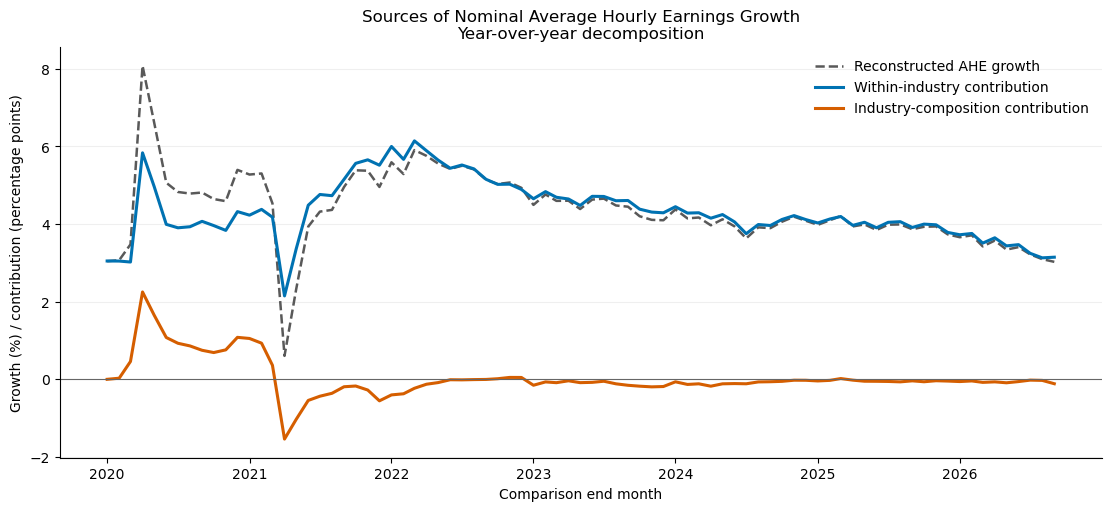

Each point compares earnings with **the same month a year earlier**. The two contributions sum to reconstructed AHE growth. Positive composition contributions add to measured growth; negative contributions subtract from it.

In [55]:
# Contributions to earnings growth over time

import matplotlib.dates as mdates

USE_ANNUAL = True  # False gives a month-over-month view.

source = annual_summary if USE_ANNUAL else monthly_summary
period_label = "Year-over-year" if USE_ANNUAL else "Month-over-month"

trend = source.sort_values("date").set_index("date")

if trend.empty:
    raise ValueError("No decomposition results are available to plot.")

# Convert dollar-per-hour contributions to percentage points.
# All three series use the same beginning-of-period earnings denominator.
trend_data = (
    trend[
        [
            "within_total",
            "composition_total",
            "reconstructed_change",
        ]
    ]
    .div(trend["reconstructed_base_ahe"], axis=0)
    .mul(100)
)

fig, ax = plt.subplots(figsize=(11, 5), constrained_layout=True)

ax.plot(
    trend_data.index,
    trend_data["reconstructed_change"],
    label="Reconstructed AHE growth",
    color="0.35",
    linestyle="--",
    linewidth=1.8,
)

ax.plot(
    trend_data.index,
    trend_data["within_total"],
    label="Within-industry contribution",
    color="#0072B2",
    linewidth=2.2,
)

ax.plot(
    trend_data.index,
    trend_data["composition_total"],
    label="Industry-composition contribution",
    color="#D55E00",
    linewidth=2.2,
)

ax.axhline(0, color="0.4", linewidth=0.8)

ax.set_title(
    "Sources of Nominal Average Hourly Earnings Growth\n"
    f"{period_label} decomposition"
)
ax.set_ylabel("Growth (%) / contribution (percentage points)")
ax.set_xlabel("Comparison end month")

ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

ax.grid(axis="y", alpha=0.2)
ax.legend(frameon=False)

for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

plt.show()

comparison_text = (
    "the same month a year earlier"
    if USE_ANNUAL
    else "the previous month"
)

display(Markdown(
    f"Each point compares earnings with **{comparison_text}**. "
    "The two contributions sum to reconstructed AHE growth. "
    "Positive composition contributions add to measured growth; "
    "negative contributions subtract from it."
))

Industry composition made a substantial positive contribution to measured earnings growth in 2020, followed by a substantial negative contribution in 2021. These movements show how changes in the distribution of paid hours can amplify or offset changes in average earnings within sectors.

From 2023 onward, reconstructed earnings growth generally tracks the within-sector contribution closely. In this decomposition, the subsequent moderation in earnings growth primarily reflects slower increases in average earnings within broad sectors.

Because these are year-over-year comparisons, movements in the chart reflect changes in both the current month and the comparison month one year earlier.

In [57]:
annual_contributions.loc[
    annual_contributions["date"].eq(COMPARISON_END)
]

,base_date,date,industry_code,industry_name,base_ahe,end_ahe,base_weight,end_weight,within_contribution,composition_contribution,lag
800,2025-09-01,2026-09-01,10000000,Mining and logging,40.32,42.17,0.005943,0.005955,0.011006,0.000504,12
801,2025-09-01,2026-09-01,20000000,Construction,40.01,41.69,0.069657,0.070232,0.117507,0.023472,12
802,2025-09-01,2026-09-01,30000000,Manufacturing,35.70,36.92,0.109152,0.110032,0.133702,0.031983,12
803,2025-09-01,2026-09-01,40000000,"Trade, transportation, and utilities",31.19,32.09,0.211312,0.212058,0.190517,0.023587,12
804,2025-09-01,2026-09-01,50000000,Information,53.06,56.08,0.023259,0.021650,0.067812,-0.087806,12
805,2025-09-01,2026-09-01,55000000,Financial activities,47.93,49.75,0.074755,0.072954,0.134415,-0.087985,12
806,2025-09-01,2026-09-01,60000000,Professional and business services,44.74,46.03,0.176576,0.176741,0.227889,0.007479,12
807,2025-09-01,2026-09-01,65000000,Private education and health services,35.69,36.44,0.194488,0.196164,0.146494,0.060436,12
808,2025-09-01,2026-09-01,70000000,Leisure and hospitality,23.00,23.90,0.093281,0.092690,0.083687,-0.013862,12
809,2025-09-01,2026-09-01,80000000,Other services,33.35,34.33,0.041577,0.041525,0.040720,-0.001760,12


#### Sector contributions: offsetting changes produce a small net effect

The small aggregate composition effect conceals offsetting sector contributions. Financial activities and information have the largest negative composition terms over the latest year. Their shares of total paid hours declined even though average hourly earnings rose within both sectors.

Positive composition terms elsewhere—particularly in private education and health services, manufacturing, and trade, transportation, and utilities—offset much of these negative contributions.


In [46]:
monthly_contributions.loc[
    monthly_contributions["date"].eq(COMPARISON_END)
]

,base_date,date,industry_code,industry_name,base_ahe,end_ahe,base_weight,end_weight,within_contribution,composition_contribution,lag
910,2026-08-01,2026-09-01,10000000,Mining and logging,41.94,42.17,0.005965,0.005955,0.001371,-0.000405,1
911,2026-08-01,2026-09-01,20000000,Construction,41.64,41.69,0.070534,0.070232,0.003519,-0.012565,1
912,2026-08-01,2026-09-01,30000000,Manufacturing,36.90,36.92,0.110010,0.110032,0.002200,0.000812,1
913,2026-08-01,2026-09-01,40000000,"Trade, transportation, and utilities",32.07,32.09,0.210801,0.212058,0.004229,0.040323,1
914,2026-08-01,2026-09-01,50000000,Information,55.58,56.08,0.021858,0.021650,0.010877,-0.011612,1
915,2026-08-01,2026-09-01,55000000,Financial activities,49.81,49.75,0.073242,0.072954,-0.004386,-0.014356,1
916,2026-08-01,2026-09-01,60000000,Professional and business services,45.81,46.03,0.177384,0.176741,0.038954,-0.029538,1
917,2026-08-01,2026-09-01,65000000,Private education and health services,36.39,36.44,0.196124,0.196164,0.009807,0.001448,1
918,2026-08-01,2026-09-01,70000000,Leisure and hospitality,23.76,23.90,0.092319,0.092690,0.012951,0.008833,1
919,2026-08-01,2026-09-01,80000000,Other services,34.23,34.33,0.041763,0.041525,0.004164,-0.008178,1


#### Latest monthly comparison: composition can still affect individual releases

Average hourly earnings increased in nine of the ten sectors, with financial activities the exception. Professional and business services illustrates the distinction between the two components: earnings within the sector increased, while its declining share of paid hours produced a negative composition term.

This monthly example shows how a modest annual composition effect can coexist with a more noticeable offset in an individual month.

#### What these results establish

The analysis separates changes in aggregate average hourly earnings into contributions from earnings within broad sectors and shifts in their shares of paid hours. It provides a way to assess whether sector composition materially changes the interpretation of the headline measure.

The within-sector component can still reflect changes in the mix of workers and jobs within each sector. It therefore does not measure wage growth for the same individual workers. The results are also nominal, descriptive, and specific to the selected comparison period and data snapshot.

In [59]:
## Some final validations


# Confirm coverage for the explicitly selected analysis window.
validate_selected_window(
    coverage,
    start_date=ANALYSIS_START,
    end_date=ANALYSIS_END,
)

run_summary = pd.Series(
    {
        "Snapshot": SNAPSHOT_PATH.name,
        "Retrieved (UTC)": metadata.get("retrieval_end_utc", "Not recorded"),
        "Analysis window": (
            f"{ANALYSIS_START:%b %Y} to {ANALYSIS_END:%b %Y}"
        ),
        "Headline comparison": (
            f"{COMPARISON_BASE:%b %Y} to {COMPARISON_END:%b %Y}"
        ),
        "Fixed-weight reference": f"{FIXED_REFERENCE_DATE:%b %Y}",
        "Selected-window coverage": "Validated",
        "Required series": len(coverage),
        "Component industries": component_panel["industry_code"].nunique(),
        "Months": component_panel["date"].nunique(),
        "Industry-month rows": len(component_panel),
    },
    name="Value",
).to_frame()

display(Markdown("## Data and validation"))
display(run_summary)

# Recompute arithmetic balances from the outputs.
weight_error = (
    weights.groupby("date")["weight"].sum(min_count=1) - 1
)

monthly_error = (
    monthly_summary["reconstructed_change"]
    - monthly_summary["within_total"]
    - monthly_summary["composition_total"]
)

annual_error = (
    annual_summary["reconstructed_change"]
    - annual_summary["within_total"]
    - annual_summary["composition_total"]
)

# These are numerical tolerances, not economic materiality thresholds.
check_inputs = [
    ("Weights sum to one", weight_error, "Share", 1e-10),
    ("Monthly decomposition balances", monthly_error, "USD/hour", 1e-10),
    ("Annual decomposition balances", annual_error, "USD/hour", 1e-10),
]

checks = pd.DataFrame(
    [
        {
            "Check": label,
            "Maximum absolute error": errors.abs().max(skipna=False),
            "Unit": unit,
            "Tolerance": tolerance,
        }
        for label, errors, unit, tolerance in check_inputs
    ]
).set_index("Check")

checks["Status"] = (
    checks["Maximum absolute error"]
    .le(checks["Tolerance"])
    .map({True: "PASS", False: "CHECK"})
)

display(Markdown("### Arithmetic checks across the analysis window"))
display(
    checks.style.format(
        {
            "Maximum absolute error": "{:.2e}",
            "Tolerance": "{:.0e}",
        }
    )
)

# Benchmark differences are separate from decomposition arithmetic.
benchmark_gaps = pd.DataFrame(
    {
        "Maximum absolute gap": reconciliation[
            ["earnings_residual", "employment_residual"]
        ].abs().max(skipna=False),
        "Unit": ["USD/hour", "Thousand employees"],
    }
).rename(
    index={
        "earnings_residual": "Published vs reconstructed AHE",
        "employment_residual": "Published vs component employment",
    }
)

display(Markdown("### Reconciliation with published totals"))
display(
    benchmark_gaps.style.format(
        {"Maximum absolute gap": "{:.6f}"}
    )
)

display(Markdown(
    "Arithmetic errors should be close to zero within numerical precision. "
    "Benchmark gaps measure agreement with the published totals and should "
    "be assessed separately. These checks establish accounting consistency; "
    "they do not establish economic causality or replace the test suite."
))

if checks["Status"].ne("PASS").any():
    raise ValueError("An arithmetic check failed; review the table above.")

## Data and validation

,Value
Snapshot,snapshot_20261017T201430156177Z.json
Retrieved (UTC),2026-10-17T20:14:30.156094Z
Analysis window,Jan 2019 to Sep 2026
Headline comparison,Sep 2025 to Sep 2026
Fixed-weight reference,Sep 2025
Selected-window coverage,Validated
Required series,33
Component industries,10
Months,93
Industry-month rows,930


### Arithmetic checks across the analysis window

,Maximum absolute error,Unit,Tolerance,Status
Check,,,,
Weights sum to one,2.22e-16,Share,1e-10,PASS
Monthly decomposition balances,1.16e-14,USD/hour,1e-10,PASS
Annual decomposition balances,9.98e-15,USD/hour,1e-10,PASS


### Reconciliation with published totals

,Maximum absolute gap,Unit
Published vs reconstructed AHE,0.006248,USD/hour
Published vs component employment,0.000000,Thousand employees


Arithmetic errors should be close to zero within numerical precision. Benchmark gaps measure agreement with the published totals and should be assessed separately. These checks establish accounting consistency; they do not establish economic causality or replace the test suite.